In [1]:
import neuralnetworkdev as nndev
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

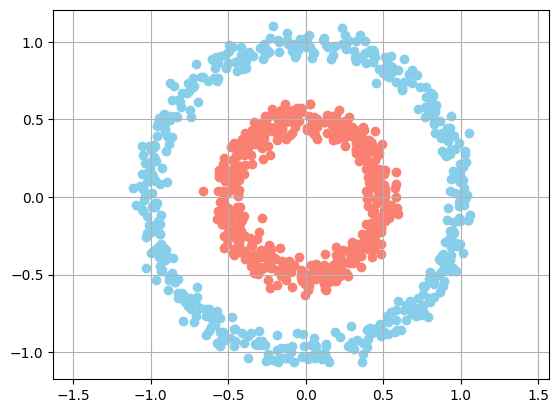

In [3]:
n = 1000
p = 2

X,Y = make_circles(n_samples=n, factor=0.5, noise=0.05)

Y = Y[:, np.newaxis]

plt.scatter(X[Y[:,0] == 0, 0], X[Y[:,0] == 0, 1], c='skyblue')
plt.scatter(X[Y[:,0] == 1, 0], X[Y[:,0] == 1, 1], c='salmon')
plt.grid()
plt.axis('equal')
plt.show()


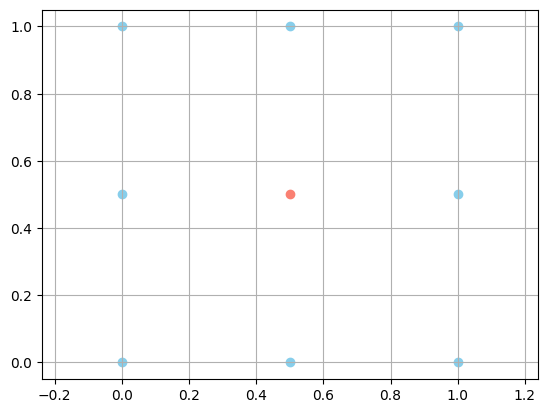

In [15]:
p = 2

X = np.array([[0., 0.], [1., 0.], [0.,1.], [1., 1.], [0.5, 0.5], [0., 0.5], [1., 0.5], [0.5, 0.], [0.5, 1]])
Y = np.array([[0.], [0.], [0.], [0.], [1.], [0.], [0.], [0.], [0.]])

plt.scatter(X[Y[:,0] == 0, 0], X[Y[:,0] == 0, 1], c='skyblue')
plt.scatter(X[Y[:,0] == 1, 0], X[Y[:,0] == 1, 1], c='salmon')
plt.grid()
plt.axis('equal')
plt.show()

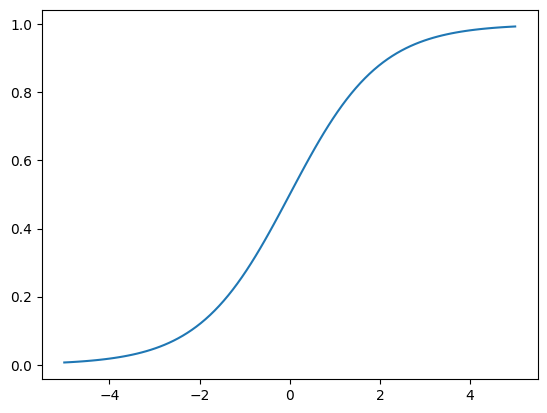

In [4]:
act_f = 'sigm'
_x = np.linspace(-5,5,100)
f, df = nndev.ActivationFunctionValidation(act_f)
plt.plot(_x, f(_x))

In [19]:
nn = nndev.FullyConnected1DModel(input_size=p, topology=[4, 6, 3, 2, 1], act_f=act_f)
losses =[]

Step 4000/5000 -> loss : 0.24963793225248082


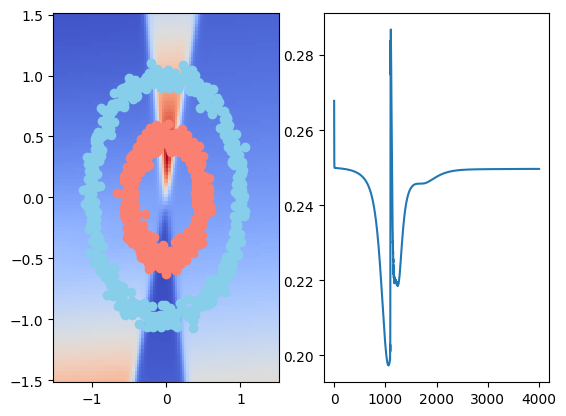

KeyboardInterrupt: 

In [20]:
import time
from IPython.display import clear_output


steps = 5000

for step in range(1, steps+1):
    _loss = nn.train(X, Y, 'MSE', learning_rate=0.009)
    losses.append(_loss)
    if step%250 == 0:
        res = 100
        _x = np.linspace(-1.5, 1.5, res)
        _y = np.linspace(-1.5, 1.5, res)
        _outputs = np.zeros((res, res))

        for i0,x0 in enumerate(_x):
            for i1,x1 in enumerate(_y):
                _outputs[i0,i1] = nn.apply(np.array([x0,x1]))[0,0]
        
        
        clear_output(wait=True)
        print(f"Step {step}/{steps} -> loss : {_loss}")
        fig,(ax1,ax2) = plt.subplots(1,2)
        ax1.pcolormesh(_x, _y, _outputs, cmap = "coolwarm")
        ax1.scatter(X[Y[:,0] == 0, 0], X[Y[:,0] == 0, 1], c='skyblue')
        ax1.scatter(X[Y[:,0] == 1, 0], X[Y[:,0] == 1, 1], c='salmon')
        ax2.plot(range(len(losses)), losses)
        plt.show()
        time.sleep(0.5)

    

#losses += nn.compile(X, Y, 'MSE', steps=1000, learning_rate=0.01, show_on_step=10)

In [ ]:
a = np.array([0.5, 0.5])
nn.apply(X)
nn.apply(a)